Total fusion strings used for plotting: 1178
Chr entries used for plotting: 1475

Chromosome-wise fusion counts:
chr22     11
chr21     15
chr18     16
chrX      18
chr16     20
chr10     23
chr9      28
chr13     32
chr19     35
chr15     41
chr4      42
chr5      50
chr20     51
chr14     53
chr2      65
chr6      70
chr7      75
chr3      88
chr8     103
chr1     117
chr12    119
chr17    190
chr11    213
Name: Chr, dtype: int64
Plot saved to: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/SV_df_DNA_Chromosome_Fusion_Counts_All.pdf
Plot saved to: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/SV_df_DNA_Chromosome_Fusion_Counts_All.png


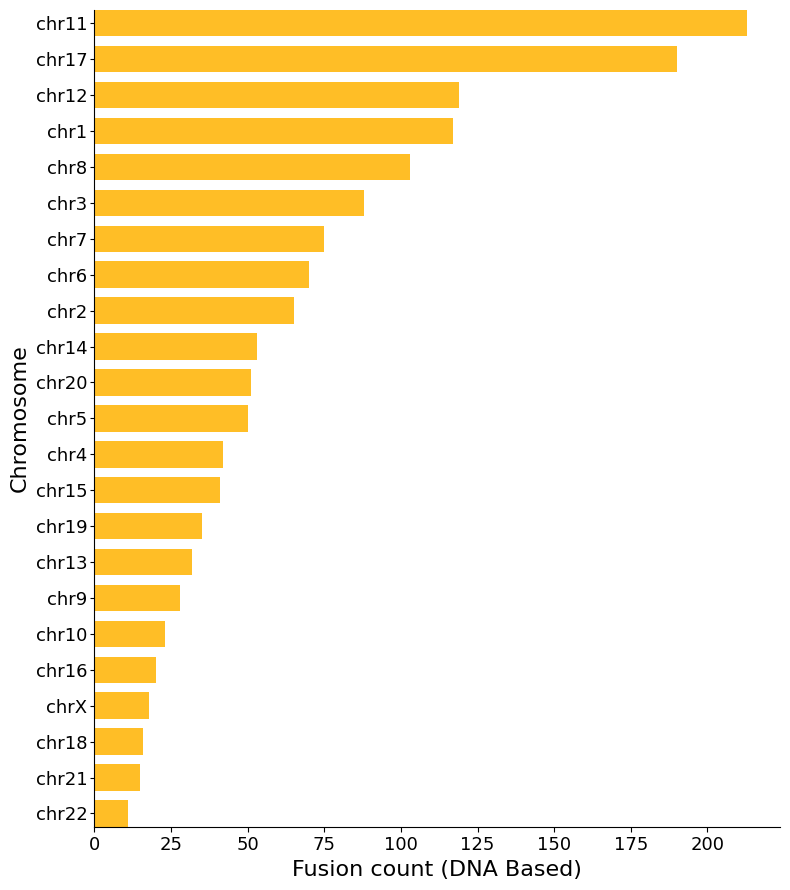

In [11]:
# Total Fusion Count across all samples identified through OGM (DNA based)
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# FILE PATH
# ============================================================
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue.csv"

out_pdf = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/SV_df_DNA_Chromosome_Fusion_Counts_All.pdf"
out_png = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/SV_df_DNA_Chromosome_Fusion_Counts_All.png"

# ============================================================
# LOAD FILE
# ============================================================
df = pd.read_csv(file_path)
df.columns = df.columns.str.strip()

# ============================================================
# FUNCTION: keep valid fusion rows and explode one fusion per row
# ============================================================
def prepare_fusion_df(input_df):
    temp = input_df.copy()

    # keep rows with valid fusion strings
    temp = temp[temp["PutativeGeneFusion"].notna()]
    temp = temp[~temp["PutativeGeneFusion"].astype(str).str.strip().isin(["", "not_applicable", "-"])]

    # keep rows with valid breakpoint chromosomes
    temp = temp[temp["RefcontigID1"].notna() & temp["RefcontigID2"].notna()].copy()
    temp["RefcontigID1"] = temp["RefcontigID1"].astype(str).str.strip()
    temp["RefcontigID2"] = temp["RefcontigID2"].astype(str).str.strip()

    temp = temp[
        ~temp["RefcontigID1"].isin(["", "nan"]) &
        ~temp["RefcontigID2"].isin(["", "nan"])
    ].copy()

    # split fusion strings into one row per fusion
    temp = (
        temp
        .assign(Fusion=temp["PutativeGeneFusion"].astype(str).str.split(";"))
        .explode("Fusion")
    )

    temp["Fusion"] = temp["Fusion"].astype(str).str.strip()
    temp = temp[temp["Fusion"] != ""].copy()

    return temp

# ============================================================
# FUNCTION: convert RefcontigID1 / RefcontigID2 into chromosome
# entries used for plotting
# One fusion contributes once per unique chromosome involved
# ============================================================
def make_chr_entry_df(input_df):
    rows = []

    for _, row in input_df.iterrows():
        chroms = sorted(set([row["RefcontigID1"], row["RefcontigID2"]]))
        for chrom in chroms:
            rows.append({
                "Fusion": row["Fusion"],
                "Chr": chrom
            })

    chr_df = pd.DataFrame(rows)
    return chr_df

# ============================================================
# PREPARE DATA
# ============================================================
fusion_df = prepare_fusion_df(df)
chr_df = make_chr_entry_df(fusion_df)

print(f"Total fusion strings used for plotting: {len(fusion_df)}")
print(f"Chr entries used for plotting: {len(chr_df)}")

# ============================================================
# COUNT FUSIONS PER CHROMOSOME
# ============================================================
count_df = chr_df["Chr"].value_counts().sort_values()

print("\nChromosome-wise fusion counts:")
print(count_df)

# ============================================================
# PLOT SETTINGS
# ============================================================
bar_height = 0.7
group_gap = 0.95
y_pos = np.arange(len(count_df)) * group_gap

fig, ax = plt.subplots(figsize=(8, 9))

ax.barh(
    y_pos,
    count_df.values,
    height=bar_height,
    color="#FFB300",
    alpha=0.85
)

# Y-axis labels
ax.set_yticks(y_pos)
ax.set_yticklabels(count_df.index)

ax.set_xlabel("Fusion count (DNA Based)", fontsize=16)
ax.set_ylabel("Chromosome", fontsize=16)

# Tick settings
ax.tick_params(axis='y', pad=2, labelsize=13, length=3)
ax.tick_params(axis='x', labelsize=13)

# Clean look
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Reduce empty vertical margins above and below bars
ax.set_ylim(y_pos[0] - bar_height / 2, y_pos[-1] + bar_height / 2)

plt.tight_layout()

plt.savefig(out_pdf, dpi=300, bbox_inches="tight")
plt.savefig(out_png, dpi=300, bbox_inches="tight")

print(f"Plot saved to: {out_pdf}")
print(f"Plot saved to: {out_png}")

plt.show()

Total RNA fusion: 411
Chr entries used for plotting: 505

Chromosome-wise RNA fusion counts:
18     3
21     5
9      6
22     7
X      8
5      8
10    10
13    11
19    13
16    13
20    15
14    16
7     17
4     21
6     22
1     25
15    26
2     27
8     32
12    40
3     41
17    60
11    79
Name: Chr, dtype: int64
Plot saved to: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/RNA_Chromosome_Fusion_Counts_All.pdf
Plot saved to: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/RNA_Chromosome_Fusion_Counts_All.png


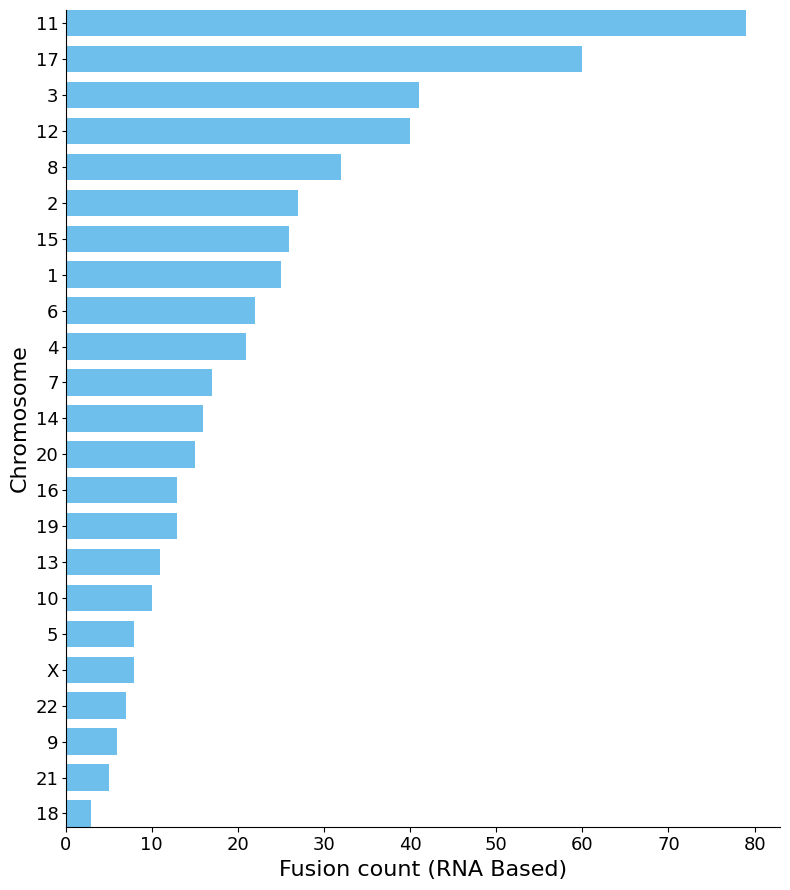

In [1]:
# Total Fusion Count across all samples identified through RNASeq (RNA based)
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# FILE PATH
# ============================================================
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/RNA_SV_with_chromosomes.csv"

out_pdf = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/RNA_Chromosome_Fusion_Counts_All.pdf"
out_png = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/RNA_Chromosome_Fusion_Counts_All.png"

# ============================================================
# LOAD FILE
# ============================================================
df = pd.read_csv(file_path)
df.columns = df.columns.str.strip()

# ============================================================
# RAW TOTAL RNA FUSION COUNT
# Same logic as your earlier script
# ============================================================
raw_rna_fusion_total = (
    df["RNAFusion"]
    .dropna()
    .astype(str)
    .str.strip()
    .loc[lambda x: ~x.isin(["", "not_applicable", "-"])]
    .shape[0]
)

# ============================================================
# FUNCTION: keep valid fusion rows for chromosome plotting
# ============================================================
def prepare_rna_fusion_df(input_df):
    temp = input_df.copy()

    # Keep valid fusion rows
    temp = temp[temp["RNAFusion"].notna()]
    temp = temp[~temp["RNAFusion"].astype(str).str.strip().isin(["", "not_applicable", "-"])]

    # Keep rows with valid chromosome information
    temp = temp[temp["ChrA"].notna() & temp["ChrB"].notna()].copy()
    temp["ChrA"] = temp["ChrA"].astype(str).str.strip()
    temp["ChrB"] = temp["ChrB"].astype(str).str.strip()

    temp = temp[
        ~temp["ChrA"].isin(["", "nan"]) &
        ~temp["ChrB"].isin(["", "nan"])
    ].copy()

    return temp

# ============================================================
# FUNCTION: create chromosome entries for plotting
# One fusion contributes once per unique chromosome involved
# ============================================================
def make_chr_entry_df(input_df):
    rows = []

    for _, row in input_df.iterrows():
        chroms = sorted(set([row["ChrA"], row["ChrB"]]))
        for chrom in chroms:
            rows.append({
                "RNAFusion": row["RNAFusion"],
                "sample": row["sample"],
                "Chr": chrom
            })

    return pd.DataFrame(rows)

# ============================================================
# PREPARE DATA FOR PLOTTING
# ============================================================
valid_fusion_df = prepare_rna_fusion_df(df)
chr_df = make_chr_entry_df(valid_fusion_df)

print(f"Total RNA fusion: {raw_rna_fusion_total}")
print(f"Chr entries used for plotting: {len(chr_df)}")

# ============================================================
# COUNT FUSIONS PER CHROMOSOME
# ============================================================
count_df = chr_df["Chr"].value_counts().sort_values()

print("\nChromosome-wise RNA fusion counts:")
print(count_df)

# ============================================================
# PLOT SETTINGS
# ============================================================
bar_height = 0.7
group_gap = 0.95
y_pos = np.arange(len(count_df)) * group_gap

fig, ax = plt.subplots(figsize=(8, 9))

ax.barh(
    y_pos,
    count_df.values,
    height=bar_height,
    color="#56B4E9",
    alpha=0.85
)

# Y-axis labels
ax.set_yticks(y_pos)
ax.set_yticklabels(count_df.index)

ax.set_xlabel("Fusion count (RNA Based)", fontsize=16)
ax.set_ylabel("Chromosome", fontsize=16)

# Tick settings
ax.tick_params(axis='y', pad=2, labelsize=13, length=3)
ax.tick_params(axis='x', labelsize=13)

# Clean look
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Reduce empty vertical margins above and below bars
ax.set_ylim(y_pos[0] - bar_height / 2, y_pos[-1] + bar_height / 2)

plt.tight_layout()

plt.savefig(out_pdf, dpi=300, bbox_inches="tight")
plt.savefig(out_png, dpi=300, bbox_inches="tight")

print(f"Plot saved to: {out_pdf}")
print(f"Plot saved to: {out_png}")

plt.show()

In [2]:
# Summarize RNA Fusion Rows Retained for Chromosome Plotting
raw_fusion_df = df[
    df["RNAFusion"].notna() &
    ~df["RNAFusion"].astype(str).str.strip().isin(["", "not_applicable", "-"])
].copy()

print("Total RNA fusion:", len(raw_fusion_df))

valid_chr_df = raw_fusion_df[
    raw_fusion_df["ChrA"].notna() &
    raw_fusion_df["ChrB"].notna()
].copy()

valid_chr_df["ChrA"] = valid_chr_df["ChrA"].astype(str).str.strip()
valid_chr_df["ChrB"] = valid_chr_df["ChrB"].astype(str).str.strip()

valid_chr_df = valid_chr_df[
    ~valid_chr_df["ChrA"].isin(["", "nan"]) &
    ~valid_chr_df["ChrB"].isin(["", "nan"])
].copy()

print("RNA fusion rows with usable ChrA/ChrB:", len(valid_chr_df))
print("Excluded before chromosome plotting:", len(raw_fusion_df) - len(valid_chr_df))

same_chr = (valid_chr_df["ChrA"] == valid_chr_df["ChrB"]).sum()
diff_chr = (valid_chr_df["ChrA"] != valid_chr_df["ChrB"]).sum()

print("Rows with same chromosome on both sides:", same_chr)
print("Rows with different chromosomes:", diff_chr)

chr_entries = same_chr + 2 * diff_chr
print("Chr entries used for plotting:", chr_entries)

Total RNA fusion: 411
RNA fusion rows with usable ChrA/ChrB: 408
Excluded before chromosome plotting: 3
Rows with same chromosome on both sides: 311
Rows with different chromosomes: 97
Chr entries used for plotting: 505


Total fusion strings used for plotting in PDO: 634
Chr entries used for plotting in PDO: 753
Total fusion strings used for plotting in Tumor: 544
Chr entries used for plotting in Tumor: 722

Chromosome-wise fusion counts:
       PDO  Tumor
chr22    4      7
chr21    7      8
chr18    6     10
chrX     8     10
chr16    3     17
chr10   18      5
chr9    16     12
chr13   14     18
chr19   14     21
chr15   31     10
chr4    19     23
chr5    26     24
chr20   16     35
chr14   34     19
chr2    28     37
chr6    51     19
chr7    39     36
chr3    29     59
chr8    44     59
chr1    57     60
chr12   33     86
chr17   95     95
chr11  161     52
Plot saved to: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/SV_df_DNA_Chromosome_Fusion_Counts_PDO_vs_Tumor.pdf
Plot saved to: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/SV_df_DNA_Chromosome_Fusion_Counts_PDO_vs_Tumor.png


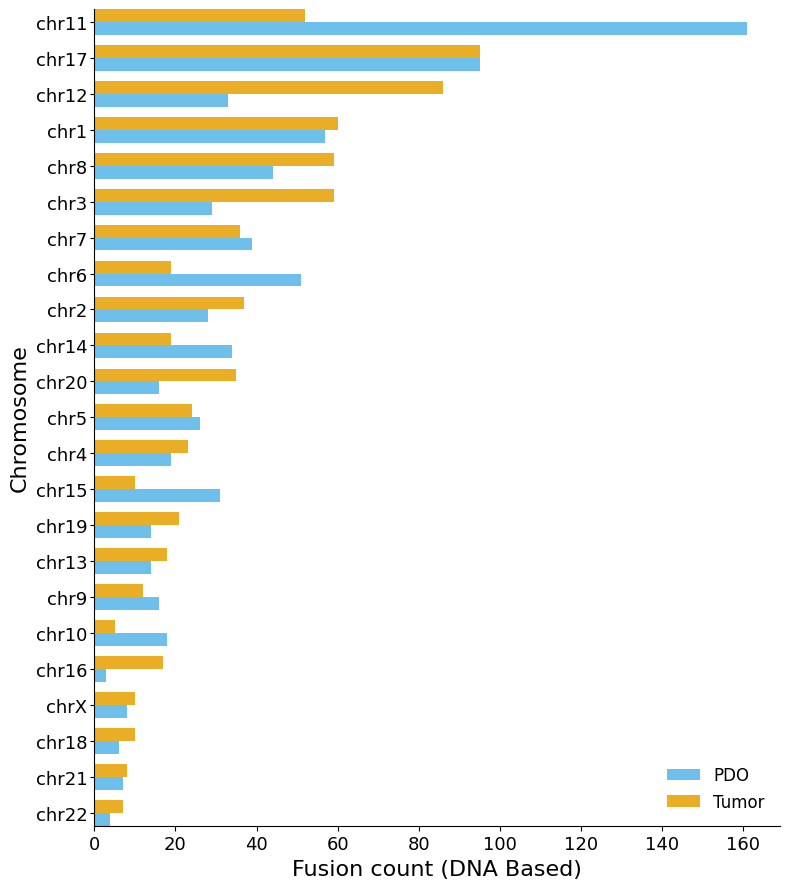

In [17]:
# Total Fusion Count across PDO and Tumor identified through OGM (DNA based)
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# FILE PATH
# ============================================================
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/SV_df_unqiue.csv"

out_pdf = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/SV_df_DNA_Chromosome_Fusion_Counts_PDO_vs_Tumor.pdf"
out_png = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/SV_df_DNA_Chromosome_Fusion_Counts_PDO_vs_Tumor.png"

# ============================================================
# LOAD FILE
# ============================================================
df = pd.read_csv(file_path)
df.columns = df.columns.str.strip()

# ============================================================
# SPLIT PDO vs TUMOR
# ============================================================
pdo_df = df[df["sample"].astype(str).str.strip().str.startswith("IPM", na=False)].copy()
tumor_df = df[df["sample"].astype(str).str.strip().str.startswith("TP", na=False)].copy()

# ============================================================
# FUNCTION: keep valid fusion rows and explode one fusion per row
# ============================================================
def prepare_fusion_df(input_df):
    temp = input_df.copy()

    # keep valid fusion strings
    temp = temp[temp["PutativeGeneFusion"].notna()]
    temp = temp[~temp["PutativeGeneFusion"].astype(str).str.strip().isin(["", "not_applicable", "-"])]

    # keep valid breakpoint chromosomes
    temp = temp[temp["RefcontigID1"].notna() & temp["RefcontigID2"].notna()].copy()
    temp["RefcontigID1"] = temp["RefcontigID1"].astype(str).str.strip()
    temp["RefcontigID2"] = temp["RefcontigID2"].astype(str).str.strip()

    temp = temp[
        ~temp["RefcontigID1"].isin(["", "nan"]) &
        ~temp["RefcontigID2"].isin(["", "nan"])
    ].copy()

    # split fusion strings into one row per fusion
    temp = (
        temp
        .assign(Fusion=temp["PutativeGeneFusion"].astype(str).str.split(";"))
        .explode("Fusion")
    )

    temp["Fusion"] = temp["Fusion"].astype(str).str.strip()
    temp = temp[temp["Fusion"] != ""].copy()

    return temp

# ============================================================
# FUNCTION: create chromosome entries for plotting
# One fusion contributes once per unique chromosome involved
# ============================================================
def make_chr_entry_df(input_df):
    rows = []

    for _, row in input_df.iterrows():
        chroms = sorted(set([row["RefcontigID1"], row["RefcontigID2"]]))
        for chrom in chroms:
            rows.append({
                "sample": row["sample"],
                "Fusion": row["Fusion"],
                "Chr": chrom
            })

    return pd.DataFrame(rows)

# ============================================================
# PREPARE DATA
# ============================================================
pdo_fusion_df = prepare_fusion_df(pdo_df)
tumor_fusion_df = prepare_fusion_df(tumor_df)

pdo_chr_df = make_chr_entry_df(pdo_fusion_df)
tumor_chr_df = make_chr_entry_df(tumor_fusion_df)

print(f"Total fusion strings used for plotting in PDO: {len(pdo_fusion_df)}")
print(f"Chr entries used for plotting in PDO: {len(pdo_chr_df)}")

print(f"Total fusion strings used for plotting in Tumor: {len(tumor_fusion_df)}")
print(f"Chr entries used for plotting in Tumor: {len(tumor_chr_df)}")

# ============================================================
# COUNT FUSIONS PER CHROMOSOME
# ============================================================
pdo_counts = pdo_chr_df["Chr"].value_counts()
tumor_counts = tumor_chr_df["Chr"].value_counts()

count_df = pd.concat(
    [pdo_counts.rename("PDO"), tumor_counts.rename("Tumor")],
    axis=1
).fillna(0)

count_df = count_df.astype(int)
count_df["Total"] = count_df["PDO"] + count_df["Tumor"]
count_df = count_df.sort_values("Total").drop(columns="Total")

print("\nChromosome-wise fusion counts:")
print(count_df)

# ============================================================
# PLOT SETTINGS
# ============================================================
bar_height = 0.34
group_gap = 0.95
y_pos = np.arange(len(count_df)) * group_gap

fig, ax = plt.subplots(figsize=(8, 9))

# PDO bar
ax.barh(
    y_pos - bar_height / 2,
    count_df["PDO"],
    height=bar_height,
    color="#56B4E9",
    alpha=0.85,
    label="PDO"
)

# Tumor bar
ax.barh(
    y_pos + bar_height / 2,
    count_df["Tumor"],
    height=bar_height,
    color="#E69F00",
    alpha=0.85,
    label="Tumor"
)

# Y-axis labels
ax.set_yticks(y_pos)
ax.set_yticklabels(count_df.index)

ax.set_xlabel("Fusion count (DNA Based)", fontsize=16)
ax.set_ylabel("Chromosome", fontsize=16)

# Tick settings
ax.tick_params(axis='y', pad=2, labelsize=13, length=3)
ax.tick_params(axis='x', labelsize=13)

# Clean look
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Reduce empty vertical margins above and below bars
ax.set_ylim(y_pos[0] - bar_height, y_pos[-1] + bar_height)

ax.legend(frameon=False, fontsize=12)

plt.tight_layout()

plt.savefig(out_pdf, dpi=300, bbox_inches="tight")
plt.savefig(out_png, dpi=300, bbox_inches="tight")

print(f"Plot saved to: {out_pdf}")
print(f"Plot saved to: {out_png}")

plt.show()

Total RNA fusion in PDO: 220
Chr entries used for plotting in PDO: 257
Total RNA fusion in Tumor: 191
Chr entries used for plotting in Tumor: 248

Chromosome-wise RNA fusion counts:
    PDO  Tumor
18    1      2
21    2      3
9     5      1
22    3      4
5     1      7
X     2      6
10    8      2
13    2      9
16    6      7
19    9      4
20    9      6
14   10      6
7     2     15
4    10     11
6    12     10
1    15     10
15   13     13
2    10     17
8    15     17
12   12     28
3    24     17
17   32     28
11   54     25
Plot saved to: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/RNA_Chromosome_Fusion_Counts_PDO_vs_Tumor.pdf
Plot saved to: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/RNA_Chromosome_Fusion_Counts_PDO_vs_Tumor.png


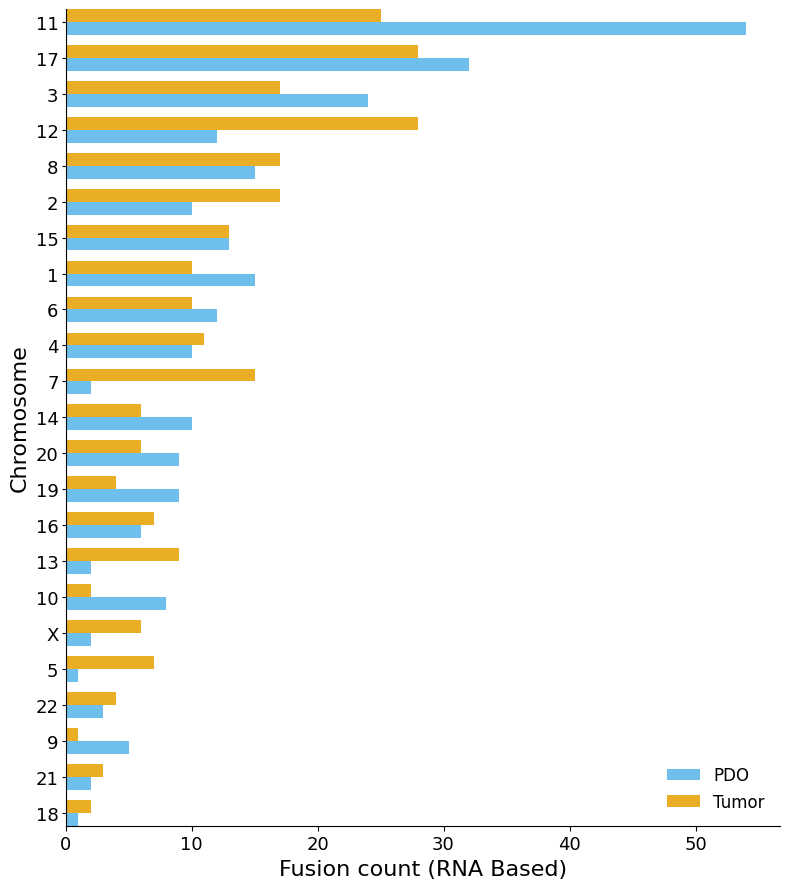

In [3]:
# Total Fusion Count across PDO and Tumor identified through RNASeq (RNA based)
# Total Fusion Count across PDO and Tumor identified through RNASeq (RNA based)
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# FILE PATH
# ============================================================
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/RNA_SV_with_chromosomes.csv"

out_pdf = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/RNA_Chromosome_Fusion_Counts_PDO_vs_Tumor.pdf"
out_png = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/RNA_Chromosome_Fusion_Counts_PDO_vs_Tumor.png"

# ============================================================
# LOAD FILE
# ============================================================
df = pd.read_csv(file_path)
df.columns = df.columns.str.strip()

# ============================================================
# SPLIT PDO vs TUMOR
# ============================================================
pdo_df = df[df["sample"].astype(str).str.strip().str.startswith("IPM", na=False)].copy()
tumor_df = df[df["sample"].astype(str).str.strip().str.startswith("TP", na=False)].copy()

# ============================================================
# FUNCTION: keep valid RNA fusion rows
# ============================================================
def prepare_rna_fusion_df(input_df):
    temp = input_df.copy()

    # keep valid fusion rows
    temp = temp[temp["RNAFusion"].notna()]
    temp = temp[~temp["RNAFusion"].astype(str).str.strip().isin(["", "not_applicable", "-"])]

    # keep valid chromosome information
    temp = temp[temp["ChrA"].notna() & temp["ChrB"].notna()].copy()
    temp["ChrA"] = temp["ChrA"].astype(str).str.strip()
    temp["ChrB"] = temp["ChrB"].astype(str).str.strip()

    temp = temp[
        ~temp["ChrA"].isin(["", "nan"]) &
        ~temp["ChrB"].isin(["", "nan"])
    ].copy()

    temp["RNAFusion"] = temp["RNAFusion"].astype(str).str.strip()
    temp = temp[temp["RNAFusion"] != ""].copy()

    return temp

# ============================================================
# FUNCTION: create chromosome entries for plotting
# One fusion contributes once per unique chromosome involved
# ============================================================
def make_chr_entry_df(input_df):
    rows = []

    for _, row in input_df.iterrows():
        chroms = sorted(set([row["ChrA"], row["ChrB"]]))
        for chrom in chroms:
            rows.append({
                "sample": row["sample"],
                "RNAFusion": row["RNAFusion"],
                "Chr": chrom
            })

    return pd.DataFrame(rows)

# ============================================================
# RAW TOTAL RNA FUSION COUNT
# ============================================================
pdo_raw_total = (
    pdo_df["RNAFusion"]
    .dropna()
    .astype(str)
    .str.strip()
    .loc[lambda x: ~x.isin(["", "not_applicable", "-"])]
    .shape[0]
)

tumor_raw_total = (
    tumor_df["RNAFusion"]
    .dropna()
    .astype(str)
    .str.strip()
    .loc[lambda x: ~x.isin(["", "not_applicable", "-"])]
    .shape[0]
)

# ============================================================
# PREPARE DATA FOR PLOTTING
# ============================================================
pdo_valid_df = prepare_rna_fusion_df(pdo_df)
tumor_valid_df = prepare_rna_fusion_df(tumor_df)

pdo_chr_df = make_chr_entry_df(pdo_valid_df)
tumor_chr_df = make_chr_entry_df(tumor_valid_df)

print(f"Total RNA fusion in PDO: {pdo_raw_total}")
print(f"Chr entries used for plotting in PDO: {len(pdo_chr_df)}")

print(f"Total RNA fusion in Tumor: {tumor_raw_total}")
print(f"Chr entries used for plotting in Tumor: {len(tumor_chr_df)}")

# ============================================================
# COUNT FUSIONS PER CHROMOSOME
# ============================================================
pdo_counts = pdo_chr_df["Chr"].value_counts()
tumor_counts = tumor_chr_df["Chr"].value_counts()

count_df = pd.concat(
    [pdo_counts.rename("PDO"), tumor_counts.rename("Tumor")],
    axis=1
).fillna(0)

count_df = count_df.astype(int)
count_df["Total"] = count_df["PDO"] + count_df["Tumor"]
count_df = count_df.sort_values("Total").drop(columns="Total")

print("\nChromosome-wise RNA fusion counts:")
print(count_df)

# ============================================================
# PLOT SETTINGS
# ============================================================
bar_height = 0.34
group_gap = 0.95
y_pos = np.arange(len(count_df)) * group_gap

fig, ax = plt.subplots(figsize=(8, 9))

# PDO bar
ax.barh(
    y_pos - bar_height / 2,
    count_df["PDO"],
    height=bar_height,
    color="#56B4E9",
    alpha=0.85,
    label="PDO"
)

# Tumor bar
ax.barh(
    y_pos + bar_height / 2,
    count_df["Tumor"],
    height=bar_height,
    color="#E69F00",
    alpha=0.85,
    label="Tumor"
)

# Y-axis labels
ax.set_yticks(y_pos)
ax.set_yticklabels(count_df.index)

ax.set_xlabel("Fusion count (RNA Based)", fontsize=16)
ax.set_ylabel("Chromosome", fontsize=16)

# Tick settings
ax.tick_params(axis='y', pad=2, labelsize=13, length=3)
ax.tick_params(axis='x', labelsize=13)

# Clean look
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Reduce empty vertical margins above and below bars
ax.set_ylim(y_pos[0] - bar_height, y_pos[-1] + bar_height)

ax.legend(frameon=False, fontsize=12)

plt.tight_layout()

plt.savefig(out_pdf, dpi=300, bbox_inches="tight")
plt.savefig(out_png, dpi=300, bbox_inches="tight")

print(f"Plot saved to: {out_pdf}")
print(f"Plot saved to: {out_png}")

plt.show()